In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# Preparing data for training, validating and testing

In [2]:
mnist_train = np.loadtxt(open("mnist-csv-format/mnist_train.csv"), delimiter=",")
x_mnist_train = mnist_train[:,1:]
y_mnist_train = mnist_train[:,0]

mnist_test = np.loadtxt(open("mnist-csv-format/mnist_test.csv"), delimiter=",")
x_test = mnist_test[:,1:]
y_test = mnist_test[:,0]

print("Size of MNIST Training Dataset =", len(mnist_train))
print("Size of MNIST Testing Dataset =", len(mnist_test))

Size of MNIST Training Dataset = 60000
Size of MNIST Testing Dataset = 10000


In [3]:
# Splitting 90% of the mnsit_train data as training data and 10% as validation data after shuffling
from sklearn.model_selection import train_test_split

x_train_t, x_val_t, y_train_t, y_val_t = train_test_split(x_mnist_train, y_mnist_train, test_size = 0.1)
print("Size of Total Training Set =", len(x_train_t))
print("Size of Total Validation Set =", len(x_val_t))
print("Size of Total Testing Set =", len(x_test))

Size of Total Training Set = 54000
Size of Total Validation Set = 6000
Size of Total Testing Set = 10000


In [4]:
# Sampling the data to increase the computational speed (only in the procedure of finding optimal hyperparameters)
p = 0.3 #Sampling percentage

x_train = x_train_t[:int(p*len(x_train_t)),:] 
x_val = x_val_t[:int(p*len(x_val_t)),:] 

y_train = y_train_t[:int(p*len(x_train_t))]
y_val = y_val_t[:int(p*len(x_val_t))] 

print("Size of Sampled Training Set ({}% of Whole Training Data)= {}".format(int(p*100), len(x_train)))
print("Size of Sampling Validation Set ({}% of Whole Validation Data)= {}".format(int(p*100), len(x_val)))

Size of Sampled Training Set (30% of Whole Training Data)= 16200
Size of Sampling Validation Set (30% of Whole Validation Data)= 1800


# Support Vector Machine (SVM)

In [5]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## 1) Linear Kernel with different Regularization Parameters (C)

### C = 1 (Default)

In [13]:
linear_cd = SVC(kernel='linear')
linear_cd.fit(x_train, y_train)

# prediction on unseen validation data
pred_linear_cd = linear_cd.predict(x_val)

In [14]:
# Report the results
print("Support Vector Classifier: Linear Kernel / C = 1 (Default Regularization Parameter)")
print("Classification Report:")
print(classification_report(y_val, pred_linear_cd))
print("Confusion_Matrix:")
print(confusion_matrix(y_val, pred_linear_cd))
print("The Accuracy is {:.4f}%".format(100 * accuracy_score(y_val, pred_linear_cd)))

Support Vector Classifier: Linear Kernel / C = 1 (Default Regularization Parameter)
Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.96      0.93       171
         1.0       0.93      0.99      0.95       202
         2.0       0.92      0.84      0.88       169
         3.0       0.86      0.88      0.87       192
         4.0       0.89      0.95      0.92       186
         5.0       0.88      0.84      0.86       161
         6.0       0.96      0.92      0.94       180
         7.0       0.91      0.96      0.93       185
         8.0       0.89      0.85      0.87       164
         9.0       0.90      0.83      0.86       190

    accuracy                           0.90      1800
   macro avg       0.90      0.90      0.90      1800
weighted avg       0.90      0.90      0.90      1800

Confusion_Matrix:
[[164   0   1   0   0   4   0   0   1   1]
 [  0 199   0   0   0   0   0   0   2   1]
 [  3   5 142   4   2   0   5 

### Validating on different C

In [15]:
c = 1e-8
acc = []    #Accurracy
reg = []      #Regularization
for i in range(9):
    # Training
    linear_c = SVC(kernel='linear', C=c)
    linear_c.fit(x_train, y_train)

    # prediction on unseen validation data
    pred_linear_c = linear_c.predict(x_val)
    
    #Evaluation
    acc.append(100 * accuracy_score(y_val, pred_linear_c))
    reg.append(c)
    c = c * 100

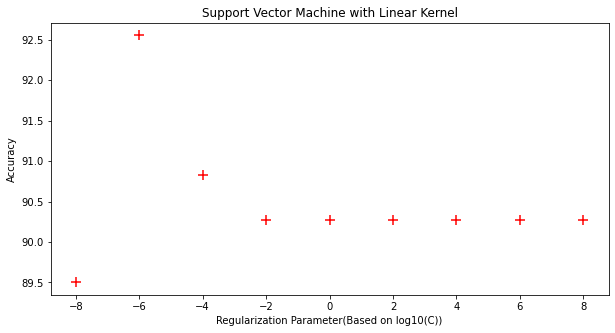

In [16]:
acc = np.array(acc)
reg = np.array(reg)

plt.figure(figsize=(10, 5))
plt.scatter(np.log10(reg), acc, s=100, c='r', marker='+')
plt.title("Support Vector Machines with Linear Kernel")
plt.xlabel("Regularization Parameter(Based on log10(C))")
plt.ylabel("Accuracy")
plt.show()

In [78]:
import pandas as pd
result1 = {'Regularization Parameter': reg, 'Accuracy': acc}
table1 = pd.DataFrame(result1)
table1

,Regularization Parameter,Accuracy
0,1.000000e-08,89.500000
1,1.000000e-06,92.555556
2,1.000000e-04,90.833333
3,1.000000e-02,90.277778
4,1.000000e+00,90.277778
5,1.000000e+02,90.277778
6,1.000000e+04,90.277778
7,1.000000e+06,90.277778
8,1.000000e+08,90.277778


### The optimal Regularization Parameter(C) according to the cross-validation

In [20]:
opt_c = reg[np.argmax(acc)]
print("The optimal Regularization Parameter is",opt_c)

The optimal Regularization Parameter is 1e-06


### By considering optimal C, we can train SVM on the whole training set and calculate accuracy on the test set

In [21]:
linear_oc = SVC(kernel='linear', C=opt_c)
linear_oc.fit(x_mnist_train, y_mnist_train)

# prediction on unseen validation data
pred_linear_oc = linear_oc.predict(x_test)

In [22]:
# Report the results
print("Support Vector Classifier: Linear Kernel / C = {} (Optimal Regularization Parameter)".format(opt_c))
print("Classification Report:")
print(classification_report(y_test, pred_linear_oc))
print("Confusion_Matrix:")
print(confusion_matrix(y_test, pred_linear_oc))
print("The Accuracy is {:.4f}%".format(100 * accuracy_score(y_test, pred_linear_oc)))

Support Vector Classifier: Linear Kernel / C = 1e-06 (Optimal Regularization Parameter)
Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97       980
         1.0       0.98      0.99      0.99      1135
         2.0       0.94      0.94      0.94      1032
         3.0       0.92      0.94      0.93      1010
         4.0       0.94      0.96      0.95       982
         5.0       0.92      0.90      0.91       892
         6.0       0.96      0.96      0.96       958
         7.0       0.96      0.94      0.95      1028
         8.0       0.94      0.91      0.93       974
         9.0       0.95      0.92      0.94      1009

    accuracy                           0.95     10000
   macro avg       0.95      0.95      0.95     10000
weighted avg       0.95      0.95      0.95     10000

Confusion_Matrix:
[[ 968    0    1    1    1    7    1    1    0    0]
 [   0 1124    2    2    0    1    2    1    3    0]
 [  10

## 2) RBF (Gaussian) Kernel with different Regularization Parameters (C) and Gammas

### C = 1 & gamma = 'scale' (Default)

In [62]:
#if gamma='scale'(default) is passed then it uses 1 / (n_features * X.var())= 1/(28*28*6169) ~= 2e-7 as value of gamma
#C(default)=1
rbf_cd_gd = SVC(kernel='rbf')
rbf_cd_gd.fit(x_train, y_train)

# prediction on unseen validation data
pred_rbf_cd_gd = rbf_cd_gd.predict(x_val)

In [63]:
# Report the results
print("Support Vector Classifier: RBF Kernel / C = 1 (Default Regularization Parameter) / gamma = 'scale' (Default Gamma)")
print("Classification Report:")
print(classification_report(y_val, pred_rbf_cd_gd))
print("Confusion_Matrix:")
print(confusion_matrix(y_val, pred_rbf_cd_gd))
print("The Accuracy is {:.4f}%".format(100 * accuracy_score(y_val, pred_rbf_cd_gd)))

Support Vector Classifier: RBF Kernel / C = 1 (Default Regularization Parameter) / gamma = 'scale' (Default Gamma)
Classification Report:
              precision    recall  f1-score   support

         0.0       0.99      0.98      0.99       171
         1.0       0.96      0.99      0.98       202
         2.0       0.98      0.93      0.95       169
         3.0       0.94      0.95      0.95       192
         4.0       0.95      0.98      0.96       186
         5.0       0.95      0.93      0.94       161
         6.0       0.99      0.98      0.99       180
         7.0       0.97      0.98      0.98       185
         8.0       0.94      0.94      0.94       164
         9.0       0.96      0.96      0.96       190

    accuracy                           0.96      1800
   macro avg       0.96      0.96      0.96      1800
weighted avg       0.96      0.96      0.96      1800

Confusion_Matrix:
[[168   0   0   0   0   1   0   0   2   0]
 [  0 200   0   1   0   0   0   0   0   1]

### Validating on different Cs and gammas

In [64]:
rbf_acc = []     #Accurracy
rbf_reg = []     #Regularization
rbf_gamma = []   #Gamma

c = [1e-6, 0.001, 1, 1000]    #Regularization list
g = [1e-7, 0.001, 1, 1000]    #Gamma list

for i in range(4):
    for j in range(4):
        # Training
        rbf_c_g = SVC(kernel='rbf', C=c[i], gamma=g[j])
        rbf_c_g.fit(x_train, y_train)

        # prediction on unseen validation data
        pred_rbf_c_g = rbf_c_g.predict(x_val)
        
        #Evaluation
        rbf_acc.append(100 * accuracy_score(y_val, pred_rbf_c_g))
        rbf_reg.append(c[i])
        rbf_gamma.append(g[j])

In [67]:
rbf_acc = np.array(rbf_acc)
rbf_reg = np.array(rbf_reg)
rbf_gamma = np.array(rbf_gamma)

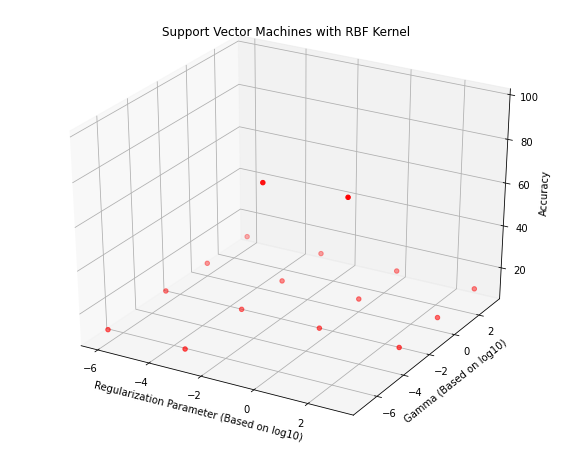

In [79]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(np.log10(rbf_reg), np.log10(rbf_gamma), rbf_acc, c='r', marker='o')
ax.set_title("Support Vector Machines with RBF Kernel")
ax.set_xlabel('Regularization Parameter (Based on log10)')
ax.set_ylabel('Gamma (Based on log10)')
ax.set_zlabel('Accuracy')
plt.show()

In [80]:
import pandas as pd
result2 = {'Regularization Parameter': rbf_reg, 'Gamma': rbf_gamma , 'Accuracy': rbf_acc}
table2 = pd.DataFrame(result2)
table2

,Regularization Parameter,Gamma,Accuracy
0,0.000001,1.000000e-07,11.222222
1,0.000001,1.000000e-03,11.222222
2,0.000001,1.000000e+00,11.222222
3,0.000001,1.000000e+03,11.222222
4,0.001000,1.000000e-07,11.222222
5,0.001000,1.000000e-03,11.222222
6,0.001000,1.000000e+00,11.222222
7,0.001000,1.000000e+03,11.222222
8,1.000000,1.000000e-07,94.666667
9,1.000000,1.000000e-03,11.222222


### The optimal Regularization Parameter(C) & Gamma according to the cross-validation

In [73]:
idx = np.argmax(rbf_acc)
rbf_opt_c = rbf_reg[idx]          #optimal Regularization Parameter 
rbf_opt_gamma = rbf_gamma[idx]    #optimal Gamma
print("The optimal Regularization Parameter is {} and the optimal Gamma is {}".format(rbf_opt_c, rbf_opt_gamma))

The optimal Regularization Parameter is 1000 and the optimal Gamma is 1e-07


### By considering optimal C & Gamma, now we can train SVM on the whole training set and calculate accuracy on the test set

In [74]:
# Since the default setting results higher accurracy, we train our SVM on the whole training set based on default setting
rbf_ocg = SVC(kernel='rbf')
rbf_ocg.fit(x_mnist_train, y_mnist_train)

# prediction on unseen validation data
pred_rbf_ocg = rbf_ocg.predict(x_test)

In [75]:
# Report the results
print("Support Vector Classifier: RBF Kernel / C = 1 (Optimal Regularization Parameter) / gamma ~=2e-7 (Optimal Gamma)")
print("Classification Report:")
print(classification_report(y_test, pred_rbf_ocg))
print("Confusion_Matrix:")
print(confusion_matrix(y_test, pred_rbf_ocg))
print("The Accuracy is {:.4f}%".format(100 * accuracy_score(y_test, pred_rbf_ocg)))

Support Vector Classifier: RBF Kernel / C = 1 (Optimal Regularization Parameter) / gamma ~=2e-7 (Optimal Gamma)
Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      0.99      0.99       980
         1.0       0.99      0.99      0.99      1135
         2.0       0.98      0.97      0.98      1032
         3.0       0.97      0.99      0.98      1010
         4.0       0.98      0.98      0.98       982
         5.0       0.99      0.98      0.98       892
         6.0       0.99      0.99      0.99       958
         7.0       0.98      0.97      0.97      1028
         8.0       0.97      0.98      0.97       974
         9.0       0.97      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000

Confusion_Matrix:
[[ 973    0    1    0    0    2    1    1    2    0]
 [   0 1126    3    1    0    1    